### DMW: Taylorpolynome und Taylorreihen - Übungen

Dieses Notebook gehört zum Wahlfach **Digitale Mathematische Werkzeuge**. Taschenrechner und Computer berechnen Werte wie e^0,3 oder sin(0,5)
mit **Polynomen**, denn Polynome brauchen nur Addition und Multiplikation. Die besten Polynome dafür sind die **Taylorpolynome**:
Sie stimmen an einer Stelle mit der Funktion im Funktionswert und in möglichst vielen Ableitungen überein.

Du beginnst mit der Tangente (lineare Näherung), baust dann Taylorpolynome höheren Grades selbst zusammen, verschiebst die Entwicklungsstelle
und untersuchst unendliche **Taylorreihen**. Am Ende steht ein überraschendes Beispiel: eine Funktion, deren Taylorreihe sie nicht darstellt.

Vorausgesetzt werden die Notebooks *Ableitungsregeln* und *Folgen und Reihen*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

**Brüche und Kommazahlen:** Python rechnet `1/6` oder `0.5` sofort als Kommazahl, bevor sympy die Zahl sieht.
Die erwarteten Ausgaben sind aber mit exakten Brüchen berechnet. Schreibe solche Zahlen deshalb mit `Rational`: `Rational(1, 6)` für 1/6,
`Rational('0.5')` für 0,5. Bei einer Division ganzer Zahlen genügt es, eine davon mit `Integer` zu schreiben: `Integer(1) / 6`.
Aufgaben, bei denen das nötig ist, haben einen entsprechenden Hinweis.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein
und legt die reellen Variablen `x`, `h` und die natürliche Zahl `k` an.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
x, h = symbols('x h', real=True)
k = symbols('k', integer=True, nonnegative=True)

## 1. Lineare Approximation

#### Die Tangente als beste Gerade

In der Nähe einer Stelle a ersetzt man f durch die Tangente: f(x) ≈ L(x) = f(a) + f'(a)·(x − a).
L stimmt in der Stelle a mit f im Funktionswert und in der Steigung überein. Der Fehler f(x) − L(x) wird klein, wenn x nahe bei a liegt.

In [ ]:
f = sqrt(x)
a = 4
L = f.subs(x, a) + diff(f, x).subs(x, a) * (x - a)
display(expand(L))
display(L.subs(x, Rational(41, 10)), N(sqrt(Rational(41, 10)), 8))
[N(f.subs(x, a + d) - L.subs(x, a + d), 3) for d in [1, Rational(1, 10), Rational(1, 100)]]

#### Aufgabe 1.1

Schreibe eine Funktion `linear(f, a)`, die die lineare Approximation zurückgibt. Teste mit f(x) = eˣ an der Stelle 0 und mit f(x) = ln(x) an der Stelle 1.

**Erwartete Ausgabe:**

$\displaystyle x + 1$

$\displaystyle x - 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def linear(f, a):
    return f.subs(x, a) + diff(f, x).subs(x, a) * (x - a)

display(linear(exp(x), 0))
linear(log(x), 1)
```

</details>

#### Aufgabe 1.2

Nähere ∛(8,3) mit der linearen Approximation von ∛x an der Stelle 8 an (genau und mit 6 Ziffern) und vergleiche mit dem genauen Wert (6 Ziffern).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{81}{40}$

$\displaystyle 2.025$

$\displaystyle 2.02469$

In [ ]:
def linear(f, a):
    return f.subs(x, a) + diff(f, x).subs(x, a) * (x - a)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def linear(f, a):
    return f.subs(x, a) + diff(f, x).subs(x, a) * (x - a)

L = linear(x**Rational(1, 3), 8)
w = L.subs(x, Rational(83, 10))
display(w, N(w, 6))
N(Rational(83, 10)**Rational(1, 3), 6)
```

</details>

#### Aufgabe 1.3

Für kleine x ist sin(x) ≈ x („Kleinwinkelnäherung“). Berechne den relativen Fehler (sin x − x)/sin x für x = 0,1, 0,2 und 0,5 mit 3 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \left[ -0.00167, \  -0.0067, \  -0.0429\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
[N((sin(w) - w) / sin(w), 3) for w in [Rational(1, 10), Rational(2, 10), Rational(5, 10)]]
```

</details>

#### Aufgabe 1.4

Nähere (1 + x)^n für kleine x linear an (Stelle 0, n als Symbol). Berechne damit 1,02¹⁰ näherungsweise und genau (4 Ziffern).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle n x + 1$

$\displaystyle \frac{6}{5}$

$\displaystyle 1.219$

In [ ]:
def linear(f, a):
    return f.subs(x, a) + diff(f, x).subs(x, a) * (x - a)
n = symbols('n')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def linear(f, a):
    return f.subs(x, a) + diff(f, x).subs(x, a) * (x - a)
n = symbols('n')
L = linear((1 + x)**n, 0)
display(L)
display(L.subs({n: 10, x: Rational(2, 100)}))
N(Rational(102, 100)**10, 4)
```

</details>

#### Aufgabe 1.5

Wie halbiert sich der Fehler? Berechne für f(x) = eˣ an der Stelle 0 den Fehler f(h) − L(h) für h = 0,2, 0,1, 0,05 (4 Ziffern). Der Fehler wird etwa geviertelt, wenn h halbiert wird.

**Erwartete Ausgabe:**

$\displaystyle \left[ 0.0214, \  0.005171, \  0.001271\right]$

In [ ]:
def linear(f, a):
    return f.subs(x, a) + diff(f, x).subs(x, a) * (x - a)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def linear(f, a):
    return f.subs(x, a) + diff(f, x).subs(x, a) * (x - a)

L = linear(exp(x), 0)
[N(exp(w) - L.subs(x, w), 4) for w in [Rational(2, 10), Rational(1, 10), Rational(5, 100)]]
```

</details>

## 2. Taylorpolynome an der Stelle 0

#### Das Konstruktionsprinzip

Gesucht ist das Polynom T(x) = a₀ + a₁x + a₂x² + ... + aₙxⁿ, das an der Stelle 0 mit f in den Ableitungen 0 bis n übereinstimmt:
T(0) = f(0), T'(0) = f'(0), ..., T⁽ⁿ⁾(0) = f⁽ⁿ⁾(0). Das sind n + 1 Gleichungen für n + 1 Koeffizienten. Allgemein ergibt sich

aₖ = f⁽ᵏ⁾(0) / k!,  also T(x) = Σₖ₌₀ⁿ f⁽ᵏ⁾(0)/k! · xᵏ

sympy kann das direkt: `series(f, x, 0, n + 1)` gibt die Entwicklung bis xⁿ und den Rest O(xⁿ⁺¹); `.removeO()` entfernt den Rest.

In [ ]:
a0, a1, a2, a3 = symbols('a0:4')
T = a0 + a1*x + a2*x**2 + a3*x**3
f = cos(x)
gleichungen = [Eq(diff(T, x, j).subs(x, 0), diff(f, x, j).subs(x, 0)) for j in range(4)]
display(gleichungen)
display(solve(gleichungen, [a0, a1, a2, a3]))
display(sum([diff(f, x, j).subs(x, 0) / factorial(j) * x**j for j in range(4)]))
series(f, x, 0, 4)

#### Aufgabe 2.1

Bestimme das Taylorpolynom 3. Grades von eˣ an der Stelle 0 mit dem Ansatz a₀ + a₁x + a₂x² + a₃x³ und den vier Bedingungen (wie im Beispiel).

**Erwartete Ausgabe:**

$\displaystyle \frac{x^{3}}{6} + \frac{x^{2}}{2} + x + 1$

In [ ]:
a0, a1, a2, a3 = symbols('a0:4')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a0, a1, a2, a3 = symbols('a0:4')
T = a0 + a1*x + a2*x**2 + a3*x**3
l = solve([Eq(diff(T, x, j).subs(x, 0), diff(exp(x), x, j).subs(x, 0)) for j in range(4)], [a0, a1, a2, a3])
T.subs(l)
```

</details>

#### Aufgabe 2.2

Schreibe eine Funktion `taylor(f, n, a=0)`, die das Taylorpolynom n-ten Grades mit der Formel Σ f⁽ʲ⁾(a)/j! · (x − a)ʲ berechnet. Teste mit sin(x), n = 7.

**Erwartete Ausgabe:**

$\displaystyle - \frac{x^{7}}{5040} + \frac{x^{5}}{120} - \frac{x^{3}}{6} + x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

taylor(sin(x), 7)
```

</details>

#### Aufgabe 2.3

Gib die Taylorpolynome von eˣ vom Grad 0 bis 4 als Liste aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1, \  x + 1, \  \frac{x^{2}}{2} + x + 1, \  \frac{x^{3}}{6} + \frac{x^{2}}{2} + x + 1, \  \frac{x^{4}}{24} + \frac{x^{3}}{6} + \frac{x^{2}}{2} + x + 1\right]$

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

[taylor(exp(x), m) for m in range(5)]
```

</details>

#### Aufgabe 2.4

Gib das Taylorpolynom 6. Grades von cos(x) mit `series` aus.

**Erwartete Ausgabe:**

$\displaystyle - \frac{x^{6}}{720} + \frac{x^{4}}{24} - \frac{x^{2}}{2} + 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
series(cos(x), x, 0, 7).removeO()
```

</details>

#### Aufgabe 2.5

Gib das Taylorpolynom 4. Grades von 1/(1 − x) und von ln(1 + x) aus.

**Erwartete Ausgabe:**

$\displaystyle x^{4} + x^{3} + x^{2} + x + 1$

$\displaystyle - \frac{x^{4}}{4} + \frac{x^{3}}{3} - \frac{x^{2}}{2} + x$

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

display(taylor(1 / (1 - x), 4))
taylor(log(1 + x), 4)
```

</details>

#### Aufgabe 2.6

Zeichne eˣ und die Taylorpolynome vom Grad 1, 2 und 3 für −3 ≤ x ≤ 2 (y von −2 bis 7, mit Legende).

**Erwartete Ausgabe:**



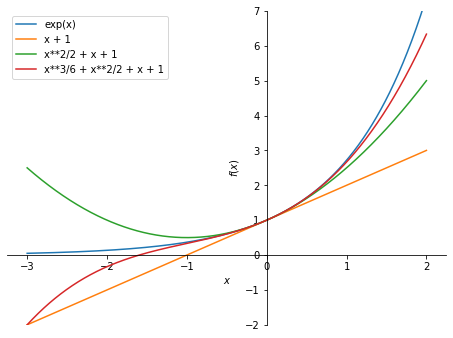

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

plot(exp(x), *[taylor(exp(x), m) for m in [1, 2, 3]], (x, -3, 2), ylim=(-2, 7), legend=True);
```

</details>

#### Aufgabe 2.7

Wie gut nähern die Taylorpolynome von eˣ die Zahl e = e¹ an? Gib für die Grade 2, 4, 6, 8, 10 den Fehler e − Tₙ(1) mit 3 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 0.218, \  0.00995, \  0.000226, \  3.06 \cdot 10^{-6}, \  2.73 \cdot 10^{-8}\right]$

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

[N(E - taylor(exp(x), m).subs(x, 1), 3) for m in [2, 4, 6, 8, 10]]
```

</details>

#### Aufgabe 2.8

Welchen Grad braucht das Taylorpolynom von sin(x), damit der Fehler bei x = 1 kleiner als 10⁻⁸ ist? (Schleife über n = 1, 3, 5, ...)

**Erwartete Ausgabe:**

$\displaystyle 11$

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

n = 1
while Abs(N(sin(1) - taylor(sin(x), n).subs(x, 1), 20)) >= Rational(1, 10**8):
    n += 2
n
```

</details>

#### Aufgabe 2.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(series(x**2 + 3*x + 1, x, 0, 5))
display(series(exp(2*x), x, 0, 3).removeO())
series(sin(x), x, 0, 2).removeO()
```

In [ ]:
display(series(x**2 + 3*x + 1, x, 0, 5))
display(series(exp(2*x), x, 0, 3).removeO())
series(sin(x), x, 0, 2).removeO()

## 3. Entwicklung an einer beliebigen Stelle

#### Taylorpolynome um x = a

An der Stelle a lautet das Taylorpolynom T(x) = Σ f⁽ᵏ⁾(a)/k! · (x − a)ᵏ. Das ist dasselbe Konstruktionsprinzip, nur **verschoben**:
Setzt man x = a + h, wird daraus ein Taylorpolynom in h an der Stelle 0, nämlich das von g(h) = f(a + h).

`series(f, x, a, n + 1)` entwickelt an der Stelle a.

In [ ]:
f = log(x)
display(series(f, x, 1, 4).removeO())
g = f.subs(x, 1 + h)
display(series(g, h, 0, 4).removeO())
plot(f, series(f, x, 1, 4).removeO(), (x, 0.1, 3), ylim=(-3, 2), legend=True);

#### Aufgabe 3.1

Gib das Taylorpolynom 3. Grades von eˣ an der Stelle 1 aus (mit der Funktion `taylor` von oben).

**Erwartete Ausgabe:**

$\displaystyle \frac{e \left(x - 1\right)^{3}}{6} + \frac{e \left(x - 1\right)^{2}}{2} + e \left(x - 1\right) + e$

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

taylor(exp(x), 3, 1)
```

</details>

#### Aufgabe 3.2

Gib das Taylorpolynom 2. Grades von √x an der Stelle 4 aus und berechne damit √4,1 (8 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle \frac{x}{4} - \frac{\left(x - 4\right)^{2}}{64} + 1$

$\displaystyle 2.0248437$

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

T = taylor(sqrt(x), 2, 4)
display(T)
N(T.subs(x, Rational(41, 10)), 8)
```

</details>

#### Aufgabe 3.3

Prüfe die Verschiebung: Das Taylorpolynom von sin(x) an der Stelle π/2 (Grad 4) ist das von cos(h) an der Stelle 0, wenn man h = x − π/2 setzt.
Berechne beide und vergleiche (Differenz vereinfacht).

**Erwartete Ausgabe:**

$\displaystyle \frac{\left(x - \frac{\pi}{2}\right)^{4}}{24} - \frac{\left(x - \frac{\pi}{2}\right)^{2}}{2} + 1$

$\displaystyle 0$

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

T1 = taylor(sin(x), 4, pi/2)
T2 = taylor(cos(x), 4).subs(x, x - pi/2)
display(T1)
simplify(T1 - T2)
```

</details>

#### Aufgabe 3.4

Ein **Polynom** ist seine eigene Taylorreihe. Entwickle f(x) = x³ − 2x + 1 an der Stelle 1 (Grad 3) und multipliziere das Ergebnis aus.

**Erwartete Ausgabe:**

$\displaystyle x + \left(x - 1\right)^{3} + 3 \left(x - 1\right)^{2} - 1$

$\displaystyle x^{3} - 2 x + 1$

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

T = taylor(x**3 - 2*x + 1, 3, 1)
display(T)
expand(T)
```

</details>

#### Aufgabe 3.5

Zeichne ln(x) und seine Taylorpolynome vom Grad 1, 3 und 5 an der Stelle 1 für 0,1 ≤ x ≤ 3 (y von −3 bis 2, mit Legende).

**Erwartete Ausgabe:**



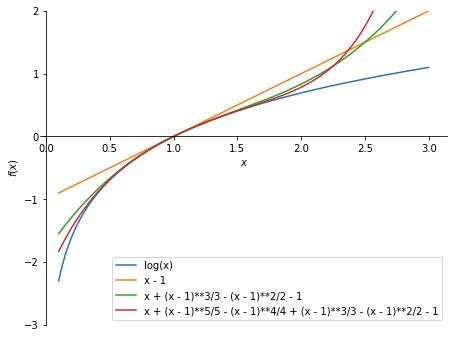

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

plot(log(x), *[taylor(log(x), m, 1) for m in [1, 3, 5]], (x, 0.1, 3), ylim=(-3, 2), legend=True);
```

</details>

## 4. Taylorreihen

#### Unendlich viele Glieder

Lässt man den Grad gegen unendlich gehen, erhält man die **Taylorreihe** Σₖ₌₀^∞ f⁽ᵏ⁾(a)/k! · (x − a)ᵏ. Für eˣ, sin(x) und cos(x) konvergiert sie
für **alle** x gegen die Funktion:

eˣ = Σ xᵏ/k!,  sin(x) = Σ (−1)ᵏ x²ᵏ⁺¹/(2k + 1)!,  cos(x) = Σ (−1)ᵏ x²ᵏ/(2k)!

Andere Reihen konvergieren nur in einem Bereich: 1/(1 − x) = Σ xᵏ (geometrische Reihe) nur für |x| < 1.

In [ ]:
display(summation(x**k / factorial(k), (k, 0, oo)))
display(summation((-1)**k * x**(2*k + 1) / factorial(2*k + 1), (k, 0, oo)))
summation(x**k, (k, 0, oo))

#### Aufgabe 4.1

Berechne die Reihe Σₖ₌₀^∞ (−1)ᵏ x²ᵏ/(2k)! mit `summation`.

**Erwartete Ausgabe:**

$\displaystyle \cos{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
summation((-1)**k * x**(2*k) / factorial(2*k), (k, 0, oo))
```

</details>

#### Aufgabe 4.2

Berechne mit der Reihe von eˣ die Summe Σₖ₌₀^∞ 2ᵏ/k! und Σₖ₌₀^∞ (−1)ᵏ/k!.

**Erwartete Ausgabe:**

$\displaystyle e^{2}$

$\displaystyle e^{-1}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(summation(2**k / factorial(k), (k, 0, oo)))
summation((-1)**k / factorial(k), (k, 0, oo))
```

</details>

#### Aufgabe 4.3

Die Taylorreihe von ln(1 + x) ist Σₖ₌₁^∞ (−1)ᵏ⁺¹ xᵏ/k. Berechne die Partialsummen mit 20 und 40 Gliedern für x = 1/2 und x = 2 (je 4 Ziffern). Für x = 2 konvergiert
die Reihe nicht.

**Erwartete Ausgabe:**

$\displaystyle \left[ 0.4055, \  0.4055, \  0.4055\right]$

$\displaystyle \left[ -3.436 \cdot 10^{4}, \  -1.817 \cdot 10^{10}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def s(w, m):
    return N(sum([(-1)**(j + 1) * Rational(w)**j / j for j in range(1, m + 1)]), 4)

display([s(Rational(1, 2), 20), s(Rational(1, 2), 40), N(log(Rational(3, 2)), 4)])
[s(2, 20), s(2, 40)]
```

</details>

#### Aufgabe 4.4

Zeichne 1/(1 − x) und die Taylorpolynome vom Grad 2, 5, 10 für −1,5 ≤ x ≤ 1 (y von −2 bis 6). Außerhalb von |x| < 1 entfernen sich die Polynome.

**Erwartete Ausgabe:**



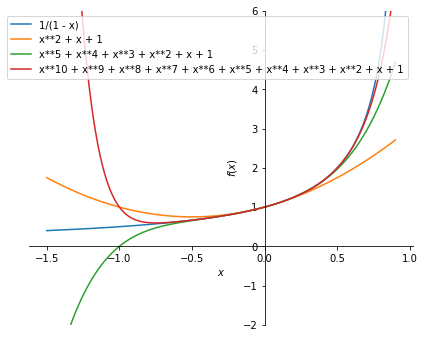

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(1 / (1 - x), *[series(1 / (1 - x), x, 0, m + 1).removeO() for m in [2, 5, 10]], (x, -1.5, 0.9), ylim=(-2, 6), legend=True);
```

</details>

#### Aufgabe 4.5

**π berechnen:** Die Taylorreihe von arctan(x) ist Σ (−1)ᵏ x²ᵏ⁺¹/(2k + 1). Mit arctan(1) = π/4 ist π = 4 · (1 − 1/3 + 1/5 − ...). Berechne die Näherung mit 100 und mit 1000 Gliedern
(je 6 Ziffern). Sie konvergiert sehr langsam.

**Erwartete Ausgabe:**

$\displaystyle \left[ 3.13159, \  3.14059, \  3.14159\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def pi_naeherung(m):
    return N(4 * sum([Rational((-1)**j, 2*j + 1) for j in range(m)]), 6)

[pi_naeherung(100), pi_naeherung(1000), N(pi, 6)]
```

</details>

#### Aufgabe 4.6

Schneller geht es mit der **Formel von Machin**: π/4 = 4·arctan(1/5) − arctan(1/239). Berechne π mit je 10 Gliedern der arctan-Reihe (15 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 3.14159265358979$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def arctan_reihe(w, m):
    return sum([(-1)**j * w**(2*j + 1) / (2*j + 1) for j in range(m)])

N(4 * (4 * arctan_reihe(Rational(1, 5), 10) - arctan_reihe(Rational(1, 239), 10)), 15)
```

</details>

## 5. Ein Gegenbeispiel

#### Eine Funktion, deren Taylorreihe sie nicht darstellt

Die Funktion f(x) = e^(−1/x) für x > 0 und f(x) = 0 für x ≤ 0 ist überall beliebig oft differenzierbar. An der Stelle 0 sind **alle** Ableitungen 0:
Die Grenzwerte der Ableitungen von rechts sind 0, und links ist f konstant 0. Ihre Taylorreihe an der Stelle 0 ist deshalb die **Nullreihe** 0 + 0·x + 0·x² + ...
Sie konvergiert zwar (gegen 0), aber für x > 0 nicht gegen f(x), denn dort ist f(x) > 0. Die Taylorreihe stellt f also nicht dar.

`Piecewise((term1, bedingung1), (term2, True))` definiert eine stückweise Funktion.

In [ ]:
f = Piecewise((exp(-1/x), x > 0), (0, True))
display(f)
display([limit(diff(exp(-1/x), x, j), x, 0, '+') for j in range(5)])
display(f.subs(x, Rational(1, 2)), N(f.subs(x, Rational(1, 2)), 4))
plot(f, (x, -1, 3));

#### Aufgabe 5.1

Gib die ersten drei Ableitungen von e^(−1/x) aus (mit `simplify`).

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{e^{- \frac{1}{x}}}{x^{2}}, \  \frac{\left(1 - 2 x\right) e^{- \frac{1}{x}}}{x^{4}}, \  \frac{\left(6 x^{2} - 6 x + 1\right) e^{- \frac{1}{x}}}{x^{6}}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
[simplify(diff(exp(-1/x), x, j)) for j in range(1, 4)]
```

</details>

#### Aufgabe 5.2

Berechne die Grenzwerte der Ableitungen 1 bis 6 von e^(−1/x) für x → 0 von rechts (Liste).

**Erwartete Ausgabe:**

$\displaystyle \left[ 0, \  0, \  0, \  0, \  0, \  0\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
[limit(diff(exp(-1/x), x, j), x, 0, '+') for j in range(1, 7)]
```

</details>

#### Aufgabe 5.3

Gib f(x) und den Wert der (Null-)Taylorreihe an den Stellen 0,1, 0,5, 1, 2 mit 4 Ziffern als Liste von Paaren aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( 4.54 \cdot 10^{-5}, \  0\right), \  \left( 0.1353, \  0\right), \  \left( 0.3679, \  0\right), \  \left( 0.6065, \  0\right)\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Piecewise((exp(-1/x), x > 0), (0, True))
[(N(f.subs(x, w), 4), 0) for w in [Rational(1, 10), Rational(1, 2), 1, 2]]
```

</details>

#### Aufgabe 5.4

Zeichne den rechten Teil e^(−1/x) für 0,02 ≤ x ≤ 1 (so sieht man, wie flach f an die x-Achse anschließt) und gib f(0,1) und f(0,05) mit 3 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 4.54 \cdot 10^{-5}, \  2.06 \cdot 10^{-9}\right]$

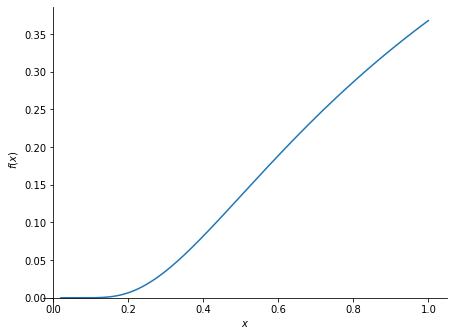

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(exp(-1/x), (x, 0.02, 1));
[N(exp(-1/w), 3) for w in [Rational(1, 10), Rational(5, 100)]]
```

</details>

## 6. Anwendungen

#### Aufgabe 6.1

**Pendel:** Für kleine Auslenkungen φ ersetzt man sin(φ) durch φ. Bis zu welchem Winkel (in Grad, ganze Zahl) ist der relative Fehler (φ − sin φ)/sin φ kleiner als 1 %?
(Schleife über ganze Grad)

**Erwartete Ausgabe:**

$\displaystyle 13$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = 1
while N((g*pi/180 - sin(g*pi/180)) / sin(g*pi/180)) < Rational(1, 100):
    g += 1
g - 1
```

</details>

#### Aufgabe 6.2

**Relativitätstheorie:** Die Energie ist E = m c² / √(1 − v²/c²). Entwickle 1/√(1 − u) an der Stelle u = 0 bis zum Grad 2 und setze u = v²/c² ein (ausmultiplizieren).
Das zweite Glied ist die bekannte kinetische Energie ½ m v².

**Erwartete Ausgabe:**

$\displaystyle \frac{3 u^{2}}{8} + \frac{u}{2} + 1$

$\displaystyle c^{2} m + \frac{m v^{2}}{2} + \frac{3 m v^{4}}{8 c^{2}}$

In [ ]:
m, c, v, uu = symbols('m c v u', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m, c, v, uu = symbols('m c v u', positive=True)
T = series(1 / sqrt(1 - uu), uu, 0, 3).removeO()
display(T)
expand(m * c**2 * T.subs(uu, v**2 / c**2))
```

</details>

#### Aufgabe 6.3

Berechne e^0,3 mit dem Taylorpolynom 5. Grades von eˣ (8 Ziffern) und den Fehler (3 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 1.3498577$

$\displaystyle 1.06 \cdot 10^{-6}$

In [ ]:
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def taylor(f, n, a=0):
    return sum([diff(f, x, j).subs(x, a) / factorial(j) * (x - a)**j for j in range(n + 1)])

T = taylor(exp(x), 5)
w = T.subs(x, Rational(3, 10))
display(N(w, 8))
N(exp(Rational(3, 10)) - w, 3)
```

</details>

#### Aufgabe 6.4

Berechne das bestimmte Integral ∫₀¹ e^(−x²) dx (keine elementare Stammfunktion!) näherungsweise, indem du das Taylorpolynom 10. Grades von e^(−x²) integrierst (8 Ziffern).
Vergleiche mit `N(Integral(...))`.

**Erwartete Ausgabe:**

$\displaystyle 0.7467292$

$\displaystyle 0.74682413$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
T = series(exp(-x**2), x, 0, 11).removeO()
display(N(integrate(T, (x, 0, 1)), 8))
N(Integral(exp(-x**2), (x, 0, 1)), 8)
```

</details>